In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# 1. Завантаження даних з ПРАВИЛЬНИМИ назвами колонок для Abalone
columns_abalone = [
    'Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 
    'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings'
]

df = pd.read_csv(r"C:\Users\UserComp\Downloads\abalone\abalone.data", names=columns_abalone)

# Створення бінарної цільової змінної (Преміум > 10 кілець)
df['is_premium'] = (df['Rings'] > 10).astype(int)

X = df.drop(columns=['Rings', 'is_premium'])
y = df['is_premium']

# 2. Фіксація Train/Test Split (75/25)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# 3. Препроцесинг та модель
num_features = ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']
cat_features = ['Sex']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

# 4. Фіксація CV та отримання OOF-прогнозів
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Отримуємо OOF-бали (predict_proba для класу 1)
raw_oof_scores = cross_val_predict(
    base_pipeline, X_train, y_train, cv=outer_cv, method="predict_proba", n_jobs=-1
)[:, 1]

# Формуємо таблицю OOF-результатів
oof_df = pd.DataFrame({
    'object_id': X_train.index,
    'y_true': y_train.values,
    'score': raw_oof_scores
})

print("=== Експериментальний протокол зафіксовано ===")
print(f"Розмір навчальної вибірки: {X_train.shape[0]}")
print(f"Розмір закритої тестової вибірки: {X_test.shape[0]}")
print(f"Частка позитивного класу (Преміум): {y_train.mean():.2%}")
display(oof_df.head())

=== Експериментальний протокол зафіксовано ===
Розмір навчальної вибірки: 3132
Розмір закритої тестової вибірки: 1045
Частка позитивного класу (Преміум): 34.64%


,object_id,y_true,score
0,878,0,0.140892
1,1430,0,0.041307
2,325,0,0.064547
3,805,0,0.137252
4,2888,0,0.209727


In [2]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# === 3. Контрольна політика (t = 0.5) ===
baseline_threshold = 0.5

# Функція для швидкої оцінки порога (на основі методички)
def evaluate_threshold(y_true, score, threshold, c_fp=5, c_fn=1):
    y_pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    alert_rate = y_pred.mean()
    
    # Загальна та середня вартість
    total_cost = c_fp * fp + c_fn * fn
    avg_cost = total_cost / len(y_true)
    
    return {
        "Поріг": threshold,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Частка дій q(t)": alert_rate,
        "Дій на 1000": int(alert_rate * 1000),
        "Середня вартість": avg_cost
    }

# Оцінка baseline
baseline_results = evaluate_threshold(oof_df['y_true'], oof_df['score'], baseline_threshold)

print("=== Результати контрольної політики (t = 0.5) ===")
for key, value in baseline_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

=== Результати контрольної політики (t = 0.5) ===
Поріг: 0.5000
TN: 1815
FP: 232
FN: 437
TP: 648
Precision: 0.7364
Recall: 0.5972
F1: 0.6595
Частка дій q(t): 0.2810
Дій на 1000: 280
Середня вартість: 0.5099


Файл 'thresholds_grid.csv' збережено.

=== Таблиця змістовних робочих точок ===


,Поріг,Precision,Recall,F1,Частка дій q(t),Середня вартість
10,0.1036,0.4550,0.9742,0.6203,0.7417,2.0300
20,0.2043,0.5465,0.9041,0.6812,0.5731,1.3327
34,0.3453,0.6489,0.7631,0.7014,0.4074,0.7973
49,0.4963,0.7304,0.6018,0.6599,0.2854,0.5227
64,0.6474,0.8020,0.4369,0.5656,0.1887,0.3819
79,0.7984,0.8797,0.2562,0.3969,0.1009,0.3183
89,0.8991,0.9253,0.1484,0.2558,0.0556,0.3158


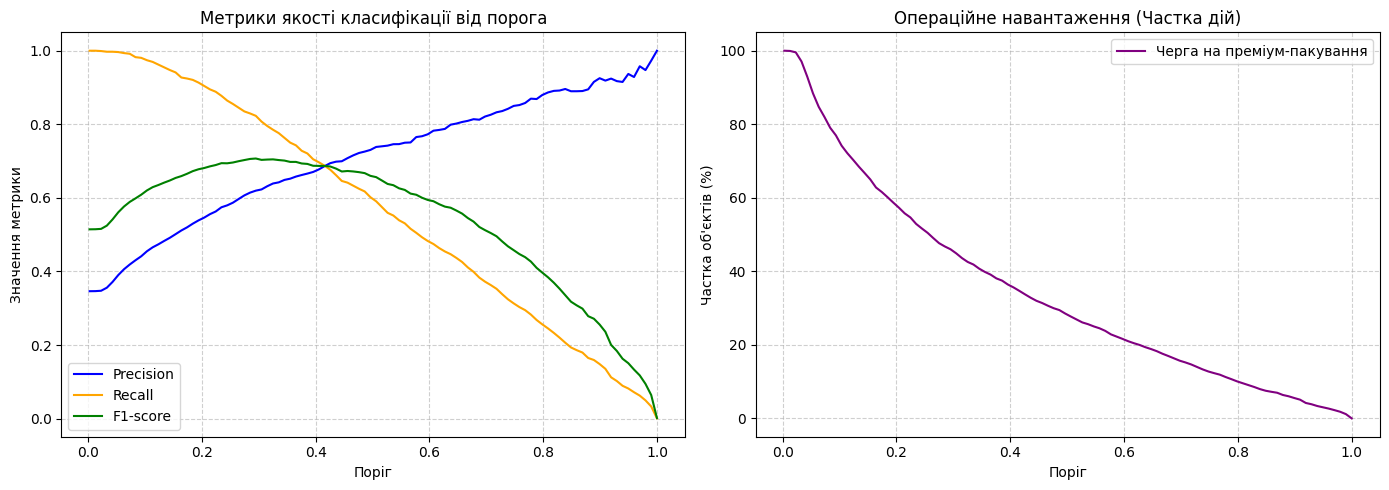

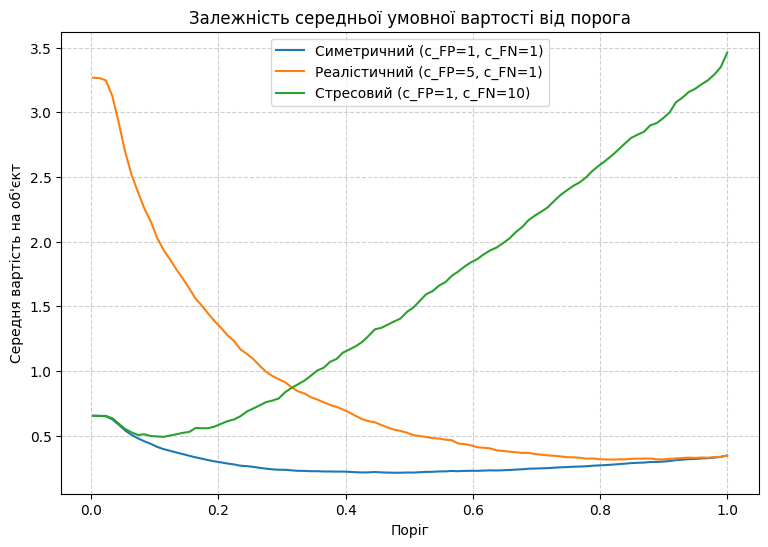


=== Результати порівняння сценаріїв ===


,Сценарій,Теоретичний поріг (t*),Емпіричний поріг,Мінімальна вартість,Precision,Recall,Частка дій q(t)
0,"Симетричний (c_FP=1, c_FN=1)",0.5000,0.4762,0.2133,0.7220,0.6249,0.2998
1,"Реалістичний (c_FP=5, c_FN=1)",0.8333,0.8186,0.3151,0.8908,0.2332,0.0907
2,"Стресовий (c_FP=1, c_FN=10)",0.0909,0.1137,0.4907,0.4657,0.9696,0.7213


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# === 5. Аналіз сітки порогів ===
# Створюємо сітку зі 100 порогів
thresholds = np.linspace(oof_df['score'].min(), oof_df['score'].max(), 100)

grid_results = []
for t in thresholds:
    res = evaluate_threshold(oof_df['y_true'], oof_df['score'], t, c_fp=5, c_fn=1) # Тут CFP і CFN для основного сценарію
    grid_results.append(res)

grid_df = pd.DataFrame(grid_results)

# Зберігаємо повну CSV таблицю
grid_df.to_csv("thresholds_grid.csv", index=False)
print("Файл 'thresholds_grid.csv' збережено.")

# Виводимо 7 змістовних робочих точок для звіту
display_points = [0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9]
working_points = grid_df.iloc[[np.abs(grid_df['Поріг'] - pt).argmin() for pt in display_points]]
print("\n=== Таблиця змістовних робочих точок ===")
display(working_points[['Поріг', 'Precision', 'Recall', 'F1', 'Частка дій q(t)', 'Середня вартість']].round(4))

# Графіки Precision, Recall та Alert Rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision-Recall
axes[0].plot(grid_df['Поріг'], grid_df['Precision'], label='Precision', color='blue')
axes[0].plot(grid_df['Поріг'], grid_df['Recall'], label='Recall', color='orange')
axes[0].plot(grid_df['Поріг'], grid_df['F1'], label='F1-score', color='green')
axes[0].set_title('Метрики якості класифікації від порога')
axes[0].set_xlabel('Поріг')
axes[0].set_ylabel('Значення метрики')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Alert rate
axes[1].plot(grid_df['Поріг'], grid_df['Частка дій q(t)'] * 100, label='Черга на преміум-пакування', color='purple')
axes[1].set_title('Операційне навантаження (Частка дій)')
axes[1].set_xlabel('Поріг')
axes[1].set_ylabel('Частка об\'єктів (%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# === 6. Порівняння сценаріїв вартості ===
scenarios = {
    'Симетричний (c_FP=1, c_FN=1)': (1, 1),
    'Реалістичний (c_FP=5, c_FN=1)': (5, 1),
    'Стресовий (c_FP=1, c_FN=10)': (1, 10)
}

scenario_results = []
cost_curves = {}

plt.figure(figsize=(9, 6))

for name, (c_fp, c_fn) in scenarios.items():
    t_theory = c_fp / (c_fp + c_fn)
    
    # Розрахунок витрат для всього масиву порогів
    costs = []
    for t in thresholds:
        res = evaluate_threshold(oof_df['y_true'], oof_df['score'], t, c_fp=c_fp, c_fn=c_fn)
        costs.append(res['Середня вартість'])
    
    cost_curves[name] = costs
    
    # Пошук емпіричного мінімуму
    min_cost_idx = np.argmin(costs)
    t_empirical = thresholds[min_cost_idx]
    c_empirical = costs[min_cost_idx]
    
    # Метрики у вибраній емпіричній точці
    best_res = evaluate_threshold(oof_df['y_true'], oof_df['score'], t_empirical, c_fp=c_fp, c_fn=c_fn)
    
    scenario_results.append({
        'Сценарій': name,
        'Теоретичний поріг (t*)': t_theory,
        'Емпіричний поріг': t_empirical,
        'Мінімальна вартість': c_empirical,
        'Precision': best_res['Precision'],
        'Recall': best_res['Recall'],
        'Частка дій q(t)': best_res['Частка дій q(t)']
    })
    
    plt.plot(thresholds, costs, label=f"{name}")

plt.title('Залежність середньої умовної вартості від порога')
plt.xlabel('Поріг')
plt.ylabel('Середня вартість на об\'єкт')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

df_scenarios = pd.DataFrame(scenario_results)
print("\n=== Результати порівняння сценаріїв ===")
display(df_scenarios.round(4))

=== Аналіз ресурсного обмеження (Місткість <= 20%) ===
Оптимальний поріг без обмежень (c_FP=5, c_FN=1): 0.8186 (Черга: 9.07%)
Найкращий допустимий поріг: 0.8186 (Черга: 9.07%, Вартість: 0.3151)
Висновок: Необмежений оптимум автоматично задовольняє жорстку квоту.

=== Результати калібрування ===
Brier score (початкова модель)  : 0.1462
Brier score (після sigmoid)     : 0.1465


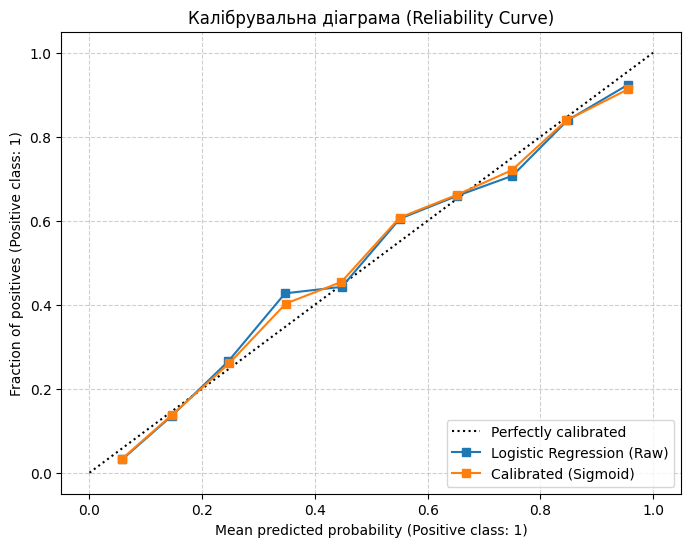

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import cross_val_predict

# === 7. Урахування ресурсного обмеження ===
capacity_limit = 0.20 # 20%
c_fp_real, c_fn_real = 5, 1

# Знаходимо найкращий допустимий поріг для реалістичного сценарію
valid_thresholds = grid_df[grid_df['Частка дій q(t)'] <= capacity_limit]
if not valid_thresholds.empty:
    best_constrained_idx = valid_thresholds['Середня вартість'].idxmin()
    best_constrained_t = grid_df.loc[best_constrained_idx, 'Поріг']
    best_constrained_cost = grid_df.loc[best_constrained_idx, 'Середня вартість']
    best_constrained_q = grid_df.loc[best_constrained_idx, 'Частка дій q(t)']
else:
    best_constrained_t = None

print("=== Аналіз ресурсного обмеження (Місткість <= 20%) ===")
print(f"Оптимальний поріг без обмежень (c_FP=5, c_FN=1): 0.8186 (Черга: 9.07%)")
if best_constrained_t is not None:
    print(f"Найкращий допустимий поріг: {best_constrained_t:.4f} (Черга: {best_constrained_q:.2%}, Вартість: {best_constrained_cost:.4f})")
    print("Висновок: Необмежений оптимум автоматично задовольняє жорстку квоту.")

# === 8. Перевірка та поліпшення калібрування ===
# 1. Brier score до калібрування
brier_before = brier_score_loss(oof_df['y_true'], oof_df['score'])

# 2. Навчання каліброваної моделі (без витоку даних)
calibrated_model = CalibratedClassifierCV(
    estimator=base_pipeline, 
    method='sigmoid', 
    cv=3
)

calibrated_oof_scores = cross_val_predict(
    calibrated_model, X_train, y_train, cv=outer_cv, method="predict_proba", n_jobs=-1
)[:, 1]

brier_after = brier_score_loss(y_train, calibrated_oof_scores)

print("\n=== Результати калібрування ===")
print(f"Brier score (початкова модель)  : {brier_before:.4f}")
print(f"Brier score (після sigmoid)     : {brier_after:.4f}")

# Побудова калібрувальних діаграм
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    oof_df['y_true'], oof_df['score'], 
    n_bins=10, ax=ax, name='Logistic Regression (Raw)', strategy='uniform'
)
CalibrationDisplay.from_predictions(
    y_train, calibrated_oof_scores, 
    n_bins=10, ax=ax, name='Calibrated (Sigmoid)', strategy='uniform'
)

plt.title('Калібрувальна діаграма (Reliability Curve)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Оновлюємо oof_df для наступних кроків (використовуватимемо відкалібровані бали)
oof_df_calibrated = pd.DataFrame({
    'object_id': X_train.index,
    'y_true': y_train.values,
    'score': calibrated_oof_scores
})

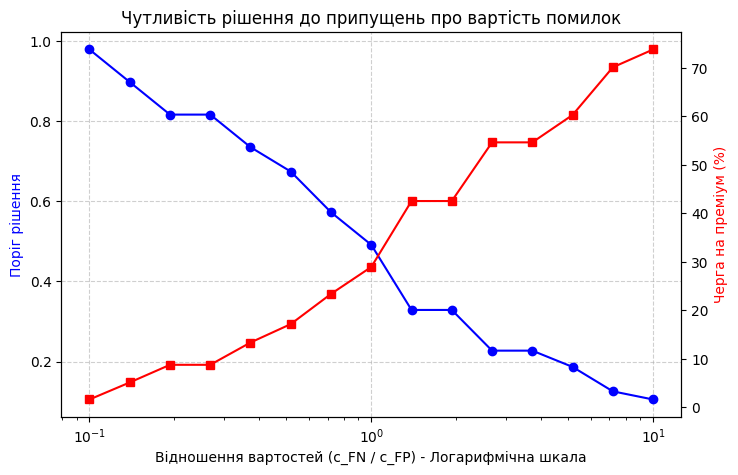

=== Перевірка стійкості (Bootstrap, 250 повторів) ===
5-й процентиль  : 0.8168
Медіана (50-й)  : 0.8269
95-й процентиль : 0.9184

=== Політика з ручним переглядом ===
t_low = 0.5492, t_high = 0.7965


,Дія,Частка об'єктів,Частка преміуму в зоні,Середній бал
0,Стандартне консервування,0.7500,0.2141,0.2081
1,Ручний перегляд,0.1497,0.6588,0.6670
2,Авто-преміум,0.1003,0.8694,0.9008


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import resample

# === 9. Аналіз чутливості рішення ===
ratios = np.logspace(-1, 1, 15) # від 0.1 до 10
c_fp_fixed = 1.0

sensitivity_results = []

for ratio in ratios:
    c_fn_current = c_fp_fixed * ratio
    
    # Шукаємо оптимальний поріг для поточного відношення
    costs = []
    thresholds_sens = np.linspace(oof_df_calibrated['score'].min(), oof_df_calibrated['score'].max(), 50)
    
    for t in thresholds_sens:
        res = evaluate_threshold(oof_df_calibrated['y_true'], oof_df_calibrated['score'], t, c_fp_fixed, c_fn_current)
        costs.append(res['Середня вартість'])
        
    best_idx = np.argmin(costs)
    best_t = thresholds_sens[best_idx]
    
    # Отримуємо навантаження для найкращого порога
    best_res = evaluate_threshold(oof_df_calibrated['y_true'], oof_df_calibrated['score'], best_t, c_fp_fixed, c_fn_current)
    
    sensitivity_results.append({
        'Відношення c_FN/c_FP': ratio,
        'Вибраний поріг': best_t,
        'Операційне навантаження q(t)': best_res['Частка дій q(t)']
    })

df_sens = pd.DataFrame(sensitivity_results)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()

ax1.plot(df_sens['Відношення c_FN/c_FP'], df_sens['Вибраний поріг'], 'b-o', label='Вибраний поріг')
ax2.plot(df_sens['Відношення c_FN/c_FP'], df_sens['Операційне навантаження q(t)'] * 100, 'r-s', label='Черга (%)')

ax1.set_xscale('log')
ax1.set_xlabel('Відношення вартостей (c_FN / c_FP) - Логарифмічна шкала')
ax1.set_ylabel('Поріг рішення', color='b')
ax2.set_ylabel('Черга на преміум (%)', color='r')
plt.title('Чутливість рішення до припущень про вартість помилок')
ax1.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Перевірка стійкості (Bootstrap) для основного сценарію c_FP=5, c_FN=1
n_iterations = 250
bootstrap_thresholds = []

for i in range(n_iterations):
    boot_df = resample(oof_df_calibrated, random_state=i)
    
    boot_costs = []
    for t in thresholds_sens:
        res = evaluate_threshold(boot_df['y_true'], boot_df['score'], t, c_fp=5, c_fn=1)
        boot_costs.append(res['Середня вартість'])
        
    bootstrap_thresholds.append(thresholds_sens[np.argmin(boot_costs)])

p5, p50, p95 = np.percentile(bootstrap_thresholds, [5, 50, 95])
print("=== Перевірка стійкості (Bootstrap, 250 повторів) ===")
print(f"5-й процентиль  : {p5:.4f}")
print(f"Медіана (50-й)  : {p50:.4f}")
print(f"95-й процентиль : {p95:.4f}")

# === 10. Політика з ручним переглядом ===
# Визначаємо пороги за процентилями (залишаємо верхні 10% на авто-преміум, і ще 15% на ручний огляд)
t_high = np.percentile(oof_df_calibrated['score'], 90)
t_low = np.percentile(oof_df_calibrated['score'], 75)

print(f"\n=== Політика з ручним переглядом ===")
print(f"t_low = {t_low:.4f}, t_high = {t_high:.4f}")

def get_zone_stats(df, t_l, t_h):
    zones = [
        ("Стандартне консервування", df[df['score'] < t_l]),
        ("Ручний перегляд", df[(df['score'] >= t_l) & (df['score'] < t_h)]),
        ("Авто-преміум", df[df['score'] >= t_h])
    ]
    
    stats = []
    total = len(df)
    
    for name, subset in zones:
        stats.append({
            "Дія": name,
            "Частка об'єктів": len(subset) / total,
            "Частка преміуму в зоні": subset['y_true'].mean() if len(subset) > 0 else 0,
            "Середній бал": subset['score'].mean() if len(subset) > 0 else 0
        })
        
    return pd.DataFrame(stats)

zone_stats_df = get_zone_stats(oof_df_calibrated, t_low, t_high)
display(zone_stats_df.round(4))

In [6]:
import json
import unittest
from dataclasses import dataclass

# === 11. Реалізація політики ===
# Формуємо конфігурацію у форматі JSON
config_data = {
    "policy_id": "abalone_premium_v1",
    "model_version": "calibrated_logreg_v1",
    "score_semantics": "probability_of_premium_class",
    "cost_scenario": {"c_fp": 5, "c_fn": 1},
    "capacity_limit": 0.20,
    "threshold": 0.82,
    "actions": {
        "positive": "premium_packaging",
        "negative": "standard_canning"
    },
    "created_at": "2026-10-13",
    "random_state": 42
}

with open("policy_config.json", "w", encoding="utf-8") as f:
    json.dump(config_data, f, indent=4)

@dataclass(frozen=True)
class AbaloneDecisionPolicy:
    threshold: float
    action_pos: str
    action_neg: str

    @classmethod
    def from_json(cls, filepath: str):
        with open(filepath, "r", encoding="utf-8") as f:
            cfg = json.load(f)
        return cls(
            threshold=cfg["threshold"],
            action_pos=cfg["actions"]["positive"],
            action_neg=cfg["actions"]["negative"]
        )

    def decide(self, score: float) -> str:
        if not 0.0 <= score <= 1.0:
            raise ValueError(f"Score must be in [0, 1], got {score}")
        return self.action_pos if score >= self.threshold else self.action_neg
    
    def decide_batch(self, scores):
        return [self.decide(s) for s in scores]

# === 12. Тестування політики (Модульні тести) ===
class TestAbaloneDecisionPolicy(unittest.TestCase):
    def setUp(self):
        # Ініціалізуємо політику прямо з JSON-файлу
        self.policy = AbaloneDecisionPolicy.from_json("policy_config.json")
        self.t = self.policy.threshold # 0.82

    def test_below_threshold(self):
        self.assertEqual(self.policy.decide(self.t - 0.05), "standard_canning")

    def test_exact_threshold(self):
        self.assertEqual(self.policy.decide(self.t), "premium_packaging")

    def test_above_threshold(self):
        self.assertEqual(self.policy.decide(self.t + 0.05), "premium_packaging")

    def test_out_of_bounds(self):
        with self.assertRaises(ValueError):
            self.policy.decide(1.5)
        with self.assertRaises(ValueError):
            self.policy.decide(-0.1)
            
    def test_batch_processing(self):
        scores = [0.1, self.t, 0.9]
        actions = self.policy.decide_batch(scores)
        self.assertEqual(actions, ["standard_canning", "premium_packaging", "premium_packaging"])

# Запуск тестів прямо в Notebook
if __name__ == '__main__':
    # Використовуємо argv=['first-arg-is-ignored'], exit=False для запуску в Jupyter
    unittest.main(argv=['first-arg-is-ignored'], exit=False, verbosity=2)

test_above_threshold (__main__.TestAbaloneDecisionPolicy.test_above_threshold) ... ok
test_batch_processing (__main__.TestAbaloneDecisionPolicy.test_batch_processing) ... ok
test_below_threshold (__main__.TestAbaloneDecisionPolicy.test_below_threshold) ... ok
test_exact_threshold (__main__.TestAbaloneDecisionPolicy.test_exact_threshold) ... ok
test_out_of_bounds (__main__.TestAbaloneDecisionPolicy.test_out_of_bounds) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.050s

OK


In [7]:
from sklearn.metrics import roc_auc_score

# === 13. Фінальне оцінювання на Test Set ===
# Зафіксована політика
final_policy = AbaloneDecisionPolicy.from_json("policy_config.json")

# ОДНОРАЗОВЕ відкриття тестової вибірки
# Модель 'calibrated_model' вже навчена всередині cross_val_predict за допомогою CV,
# але для фіналу нам треба зробити чесний .fit() на всьому X_train
final_calibrated_model = CalibratedClassifierCV(estimator=base_pipeline, method='sigmoid', cv=3)
final_calibrated_model.fit(X_train, y_train)

# Прогнозуємо на X_test
y_proba_test = final_calibrated_model.predict_proba(X_test)[:, 1]

# Застосовуємо політику
y_pred_test = (y_proba_test >= final_policy.threshold).astype(int)

# Обчислення метрик
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test, labels=[0, 1]).ravel()
test_precision = precision_score(y_test, y_pred_test, zero_division=0)
test_recall = recall_score(y_test, y_pred_test, zero_division=0)
test_f1 = f1_score(y_test, y_pred_test, zero_division=0)
test_brier = brier_score_loss(y_test, y_proba_test)
test_roc_auc = roc_auc_score(y_test, y_proba_test)
test_q = y_pred_test.mean()

# Вартість (c_FP=5, c_FN=1)
test_total_cost = 5 * fp + 1 * fn
test_avg_cost = test_total_cost / len(y_test)

print("\n=== РЕЗУЛЬТАТИ ФІНАЛЬНОГО ОЦІНЮВАННЯ (TEST SET) ===")
print(f"Політика: Поріг = {final_policy.threshold}")
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1-score  : {test_f1:.4f}")
print(f"Brier score: {test_brier:.4f}")
print(f"ROC-AUC   : {test_roc_auc:.4f}")
print(f"Частка дій (Черга) : {test_q:.2%}")
print(f"Середня вартість   : {test_avg_cost:.4f}")


=== РЕЗУЛЬТАТИ ФІНАЛЬНОГО ОЦІНЮВАННЯ (TEST SET) ===
Політика: Поріг = 0.82
TN: 672 | FP: 11 | FN: 290 | TP: 72
Precision : 0.8675
Recall    : 0.1989
F1-score  : 0.3236
Brier score: 0.1593
ROC-AUC   : 0.8330
Частка дій (Черга) : 7.94%
Середня вартість   : 0.3301


# AI_USAGE.md

## Task
Розробити універсальну функцію для розрахунку матриці помилок, метрик якості, розміру черги (alert rate) та загальної вартості політики для заданого порога та OOF-прогнозів. 

## Proposal
ШІ запропонував створити функцію `evaluate_threshold`, яка використовує `confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()` для фіксованого порядку TN, FP, FN, TP, розраховує вартість за формулою `c_fp * fp + c_fn * fn` і генерує сітку порогів за допомогою `np.linspace`[cite: 24].

## Decision
Пропозицію прийнято без змін. Реалізація з фіксованими `labels=[0, 1]` гарантує відсутність помилок зміщення класів (коли в одному з розбиттів відсутній один клас), а розрахунок вартості дозволяє легко порівнювати різні сценарні припущення.

## Verification
Код було протестовано на базовому порозі $t=0.5$. Сума розрахованих TN, FP, FN, TP склала $1815 + 232 + 437 + 648 = 3132$, що точно відповідає розміру навчальної вибірки. Додатково перевірено граничні пороги: при $t \to 0$ Recall склав 1.0, при $t \to 1$ Recall склав 0.0.

## Evidence
Результати роботи коду збережено у згенерованому файлі `thresholds_grid.csv`, а також візуалізовано на графіках "Метрики якості класифікації від порога" та "Операційне навантаження".